<h1> Milestone 3 - Workshop </h1>

In [2]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler

<h3> What needs to be done </h3>

We have 3 datasets of the 5 in our section of Aviation System Performance that we want to examine for our airline departure delay problem: Can we find the factors that exhibit the most significant impact on a flight NOT operating on schedule? Examining weather-related and non weather-related delay factors.

- 2015 Flight Delay + Cancellations Dataset: https://www.kaggle.com/datasets/usdot/flight-delays
- 2019 Flight Delay + Causes Dataset: https://www.kaggle.com/datasets/undersc0re/flight-delay-and-causes
- 2019 Flight Delay Dataset + Weather: https://www.kaggle.com/datasets/threnjen/2019-airline-delays-and-cancellations

For each dataset, we want to:

- Preprocess (Identifying and handling missing values/duplicate rows, encoding categorical variables, standardizing units, assessing if datasets can be merged, filtering unrealistic values)
- Univariate Analysis (Histograms and their variants, grouped histograms by variable, outlier detection, bar plots for categorical variables)
- Bivariate Analysis (Correlations, scatterplots on variables with large correlations, possible time series applications, grouped means/medians/modes)

These will fuel our conclusions:

- What aspects of the data were unexpected?
- Will we need to disqualify any datasets because of problems we uncovered in the data? Can these datasets be merged?
- What kind of supervised/unsupervised analyses are suggested by your work? (Depending on the target variable, this could be regression OR classification)

Some other helpful guidelines:

- You should include 6-8 figures/graphs in the body of the paper (size-wise, a single page should fit 6 figures), so be sure to generate as much as you can first then scale down

<h3> Dataset Downloads </h3>

In [6]:
d15 = pd.read_csv('flights_2015.csv', low_memory = False)
d15.info()

<class 'pandas.DataFrame'>
RangeIndex: 5819079 entries, 0 to 5819078
Data columns (total 31 columns):
 #   Column               Dtype  
---  ------               -----  
 0   YEAR                 int64  
 1   MONTH                int64  
 2   DAY                  int64  
 3   DAY_OF_WEEK          int64  
 4   AIRLINE              str    
 5   FLIGHT_NUMBER        int64  
 6   TAIL_NUMBER          str    
 7   ORIGIN_AIRPORT       str    
 8   DESTINATION_AIRPORT  str    
 9   SCHEDULED_DEPARTURE  int64  
 10  DEPARTURE_TIME       float64
 11  DEPARTURE_DELAY      float64
 12  TAXI_OUT             float64
 13  WHEELS_OFF           float64
 14  SCHEDULED_TIME       float64
 15  ELAPSED_TIME         float64
 16  AIR_TIME             float64
 17  DISTANCE             int64  
 18  WHEELS_ON            float64
 19  TAXI_IN              float64
 20  SCHEDULED_ARRIVAL    int64  
 21  ARRIVAL_TIME         float64
 22  ARRIVAL_DELAY        float64
 23  DIVERTED             int64  
 24  CANCELLED

<h2> Dataset 1: 2015 Flight Delays and Causes </h2>

<h3> Data Dictionary </h3>

ALL TIMES ARE IN MILITARY TIME, ARRIVAL AND DEPARTURE TIMES ARE ADJUSTED WITH LOCAL TIMEZONES

- YEAR: Year of the flight trip
- MONTH: Month of the flight trip
- DAY: Day of the flight trip
- DAY_OF_WEEK: Day of week of the flight trip
- AIRLINE: Airline identifier
- FLIGHT_NUMBER: Flight identifier
- TAIL_NUMBER: Aircrage identifier
- ORIGIN_AIRPORT: Starting airport
- DESTINATION_AIRPORT: Destination airport
- SCHEDULED_DEPARTURE: Planned departure time
- DEPARTURE_TIME: WHEELS_OFF - TAXI_OUT
- DEPARTURE_DELAY: Total delay on departure (minutes)
- TAXI_OUT: Time duration elapsed between the origin airport gate and wheels off (minutes)
- WHEELS_OFF: The time point that the aircraft's wheels leave the ground
- SCHEDULED_TIME: Planned time amount for the flight trip
- ELAPSED_TIME: TAXI_OUT + AIR_TIME + TAXI_IN (minutes)
- AIR TIME: Time duration between WHEELS_OFF and WHEELS_ON times (minutes)
- DISTANCE: Distance between 2 airports (miles)
- WHEELS_ON: The time point that the aircraft's wheels touch on the ground
- TAXI_IN: The time duration elapsed between wheels-on and gate arrival at the destination airport (minutes)
- SCHEDULED_ARRIVAL: Arrival time
- ARRIVAL_TIME: WHEELS_ON + TAXI_IN
- ARRIVAL_DELAY: WHEELS_ON + TAXI_IN - SCHEDULED_ARRIVAL (minutes; if this value is positive, that means the flight got in early)
- DIVERTED: Aircraft landed on airport that out of schedule (0 or 1)
- CANCELLED: Flight Cancelled (1 = cancelled)
- CANCELLATION_REASON: Reason for Cancellation of flight: A - Airline/Carrier; B - Weather; C - National Air System; D - Security
- AIR_SYSTEM_DELAY: Delay caused by air system (minutes)
- SECURITY_DELAY: Delay caused by security (minutes)
- AIRLINE_DELAY: Delay caused by the airline (minutes)
- LATE_AIRCRAFT_DELAY: Delay caused by aircraft (minutes)
- WEATHER_DELAY: Delay caused by weather (minutes)

<h3> Preprocessing </h3>

In [11]:
all15 = d15.copy()

In [12]:
all15.head(10)

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,408.0,-22.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,741.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,811.0,5.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,756.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,259.0,-21.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
5,2015,1,1,4,DL,806,N3730B,SFO,MSP,25,...,610.0,8.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
6,2015,1,1,4,NK,612,N635NK,LAS,MSP,25,...,509.0,-17.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
7,2015,1,1,4,US,2013,N584UW,LAX,CLT,30,...,753.0,-10.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
8,2015,1,1,4,AA,1112,N3LAAA,SFO,DFW,30,...,532.0,-13.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
9,2015,1,1,4,DL,1173,N826DN,LAS,ATL,30,...,656.0,-15.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


<h3> Duplicate Rows, Missing Values </h3>

In [14]:
dupes_15 = all15[all15.duplicated()]
dupes_15

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY


In [15]:
print('Checking the columns for null values:')
print()

for col in all15:
        rows_with_null = all15[all15[col].isnull()]
        print(col, len(rows_with_null))

Checking the columns for null values:

YEAR 0
MONTH 0
DAY 0
DAY_OF_WEEK 0
AIRLINE 0
FLIGHT_NUMBER 0
TAIL_NUMBER 14721
ORIGIN_AIRPORT 0
DESTINATION_AIRPORT 0
SCHEDULED_DEPARTURE 0
DEPARTURE_TIME 86153
DEPARTURE_DELAY 86153
TAXI_OUT 89047
WHEELS_OFF 89047
SCHEDULED_TIME 6
ELAPSED_TIME 105071
AIR_TIME 105071
DISTANCE 0
WHEELS_ON 92513
TAXI_IN 92513
SCHEDULED_ARRIVAL 0
ARRIVAL_TIME 92513
ARRIVAL_DELAY 105071
DIVERTED 0
CANCELLED 0
CANCELLATION_REASON 5729195
AIR_SYSTEM_DELAY 4755640
SECURITY_DELAY 4755640
AIRLINE_DELAY 4755640
LATE_AIRCRAFT_DELAY 4755640
WEATHER_DELAY 4755640


<h3> Dummy-ing the null values in delay reason columns </h3>

In [17]:
all15[['AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY']] = all15[['AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY']].fillna(0)

In [18]:
print('Checking the columns for null values:')
print()

for col in all15:
        rows_with_null = all15[all15[col].isnull()]
        print(col, len(rows_with_null))

Checking the columns for null values:

YEAR 0
MONTH 0
DAY 0
DAY_OF_WEEK 0
AIRLINE 0
FLIGHT_NUMBER 0
TAIL_NUMBER 14721
ORIGIN_AIRPORT 0
DESTINATION_AIRPORT 0
SCHEDULED_DEPARTURE 0
DEPARTURE_TIME 86153
DEPARTURE_DELAY 86153
TAXI_OUT 89047
WHEELS_OFF 89047
SCHEDULED_TIME 6
ELAPSED_TIME 105071
AIR_TIME 105071
DISTANCE 0
WHEELS_ON 92513
TAXI_IN 92513
SCHEDULED_ARRIVAL 0
ARRIVAL_TIME 92513
ARRIVAL_DELAY 105071
DIVERTED 0
CANCELLED 0
CANCELLATION_REASON 5729195
AIR_SYSTEM_DELAY 0
SECURITY_DELAY 0
AIRLINE_DELAY 0
LATE_AIRCRAFT_DELAY 0
WEATHER_DELAY 0


<h3> What's going on w/ the canceled flights? </h3>

In [20]:
section = all15[all15['CANCELLATION_REASON'].notnull() & all15['CANCELLED'] == 1]
len(section)

89884

All cancelled flights will have a non-null cancellation reason.

In [22]:
len(all15) - len(section) #every flight with a null cancellation reason wasn't cancelled

5729195

In [23]:
all15['CANCELLATION_REASON'] = all15['CANCELLATION_REASON'].fillna('Not Canceled')

In [24]:
print('Checking the columns for null values:')
print()

for col in all15:
        rows_with_null = all15[all15[col].isnull()]
        print(col, len(rows_with_null))

Checking the columns for null values:

YEAR 0
MONTH 0
DAY 0
DAY_OF_WEEK 0
AIRLINE 0
FLIGHT_NUMBER 0
TAIL_NUMBER 14721
ORIGIN_AIRPORT 0
DESTINATION_AIRPORT 0
SCHEDULED_DEPARTURE 0
DEPARTURE_TIME 86153
DEPARTURE_DELAY 86153
TAXI_OUT 89047
WHEELS_OFF 89047
SCHEDULED_TIME 6
ELAPSED_TIME 105071
AIR_TIME 105071
DISTANCE 0
WHEELS_ON 92513
TAXI_IN 92513
SCHEDULED_ARRIVAL 0
ARRIVAL_TIME 92513
ARRIVAL_DELAY 105071
DIVERTED 0
CANCELLED 0
CANCELLATION_REASON 0
AIR_SYSTEM_DELAY 0
SECURITY_DELAY 0
AIRLINE_DELAY 0
LATE_AIRCRAFT_DELAY 0
WEATHER_DELAY 0


<h3> Null Tail Numbers </h3>

In [26]:
section = all15[all15['TAIL_NUMBER'].isnull()]
section.info()

<class 'pandas.DataFrame'>
Index: 14721 entries, 297 to 5818157
Data columns (total 31 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   YEAR                 14721 non-null  int64  
 1   MONTH                14721 non-null  int64  
 2   DAY                  14721 non-null  int64  
 3   DAY_OF_WEEK          14721 non-null  int64  
 4   AIRLINE              14721 non-null  str    
 5   FLIGHT_NUMBER        14721 non-null  int64  
 6   TAIL_NUMBER          0 non-null      str    
 7   ORIGIN_AIRPORT       14721 non-null  str    
 8   DESTINATION_AIRPORT  14721 non-null  str    
 9   SCHEDULED_DEPARTURE  14721 non-null  int64  
 10  DEPARTURE_TIME       0 non-null      float64
 11  DEPARTURE_DELAY      0 non-null      float64
 12  TAXI_OUT             0 non-null      float64
 13  WHEELS_OFF           0 non-null      float64
 14  SCHEDULED_TIME       14721 non-null  float64
 15  ELAPSED_TIME         0 non-null      float64
 16

Flights with no tail number appear to be cancelled flights.

In [28]:
all15['TAIL_NUMBER'] = all15['TAIL_NUMBER'].fillna('No Tail')

In [29]:
print('Checking the columns for null values:')
print()

for col in all15:
        rows_with_null = all15[all15[col].isnull()]
        print(col, len(rows_with_null))

Checking the columns for null values:

YEAR 0
MONTH 0
DAY 0
DAY_OF_WEEK 0
AIRLINE 0
FLIGHT_NUMBER 0
TAIL_NUMBER 0
ORIGIN_AIRPORT 0
DESTINATION_AIRPORT 0
SCHEDULED_DEPARTURE 0
DEPARTURE_TIME 86153
DEPARTURE_DELAY 86153
TAXI_OUT 89047
WHEELS_OFF 89047
SCHEDULED_TIME 6
ELAPSED_TIME 105071
AIR_TIME 105071
DISTANCE 0
WHEELS_ON 92513
TAXI_IN 92513
SCHEDULED_ARRIVAL 0
ARRIVAL_TIME 92513
ARRIVAL_DELAY 105071
DIVERTED 0
CANCELLED 0
CANCELLATION_REASON 0
AIR_SYSTEM_DELAY 0
SECURITY_DELAY 0
AIRLINE_DELAY 0
LATE_AIRCRAFT_DELAY 0
WEATHER_DELAY 0


<h3> Null Values for Scheduled Time </h3>

In [31]:
section = all15[all15['SCHEDULED_TIME'].isnull()][['SCHEDULED_TIME', 'DIVERTED', 'CANCELLED', 'CANCELLATION_REASON']]
section

,SCHEDULED_TIME,DIVERTED,CANCELLED,CANCELLATION_REASON
483174,NaN,0,1,B
619941,NaN,0,1,B
1720237,NaN,1,0,Not Canceled
1820960,NaN,0,1,B
2031482,NaN,0,1,B
2034453,NaN,0,1,C


Of the 6 flights with null scheduled time, 5 were canceled and 1 was diverted. I'm down to drop them.

In [33]:
all15 = all15.dropna(subset=['SCHEDULED_TIME'])

In [34]:
print('Checking the columns for null values:')
print()

for col in all15:
        rows_with_null = all15[all15[col].isnull()]
        print(col, len(rows_with_null))

Checking the columns for null values:

YEAR 0
MONTH 0
DAY 0
DAY_OF_WEEK 0
AIRLINE 0
FLIGHT_NUMBER 0
TAIL_NUMBER 0
ORIGIN_AIRPORT 0
DESTINATION_AIRPORT 0
SCHEDULED_DEPARTURE 0
DEPARTURE_TIME 86153
DEPARTURE_DELAY 86153
TAXI_OUT 89047
WHEELS_OFF 89047
SCHEDULED_TIME 0
ELAPSED_TIME 105065
AIR_TIME 105065
DISTANCE 0
WHEELS_ON 92507
TAXI_IN 92507
SCHEDULED_ARRIVAL 0
ARRIVAL_TIME 92507
ARRIVAL_DELAY 105065
DIVERTED 0
CANCELLED 0
CANCELLATION_REASON 0
AIR_SYSTEM_DELAY 0
SECURITY_DELAY 0
AIRLINE_DELAY 0
LATE_AIRCRAFT_DELAY 0
WEATHER_DELAY 0


<h3>EQUAL Null Values for (Presumedly) Canceled Flights </h3>

In [36]:
# pulling the null values we're seeing for cancelled flights

cancel = all15[all15['CANCELLED'] == 1][['DEPARTURE_TIME', 'DEPARTURE_DELAY', 'TAXI_OUT',
                                         'WHEELS_OFF', 'ELAPSED_TIME', 'AIR_TIME',
                                         'WHEELS_ON', 'TAXI_IN', 'ARRIVAL_TIME',
                                         'ARRIVAL_DELAY']]
cancel.head()

,DEPARTURE_TIME,DEPARTURE_DELAY,TAXI_OUT,WHEELS_OFF,ELAPSED_TIME,AIR_TIME,WHEELS_ON,TAXI_IN,ARRIVAL_TIME,ARRIVAL_DELAY
32,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
42,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
68,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
82,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [37]:
#finding values in this section that aren't null

section = cancel.notnull()
len(section)

89879

So here's what we have at this point:

- cancelled flights have no value departure time or departure delay, or most of the other variables pertaining to the flight

ngl I think we need to just separate the cancelled and non-cancelled flights

In [39]:
all15 = all15.dropna(subset=['SCHEDULED_TIME'])

In [40]:
print('Checking the columns for null values:')
print()

for col in all15:
        rows_with_null = all15[all15[col].isnull()]
        print(col, len(rows_with_null))

Checking the columns for null values:

YEAR 0
MONTH 0
DAY 0
DAY_OF_WEEK 0
AIRLINE 0
FLIGHT_NUMBER 0
TAIL_NUMBER 0
ORIGIN_AIRPORT 0
DESTINATION_AIRPORT 0
SCHEDULED_DEPARTURE 0
DEPARTURE_TIME 86153
DEPARTURE_DELAY 86153
TAXI_OUT 89047
WHEELS_OFF 89047
SCHEDULED_TIME 0
ELAPSED_TIME 105065
AIR_TIME 105065
DISTANCE 0
WHEELS_ON 92507
TAXI_IN 92507
SCHEDULED_ARRIVAL 0
ARRIVAL_TIME 92507
ARRIVAL_DELAY 105065
DIVERTED 0
CANCELLED 0
CANCELLATION_REASON 0
AIR_SYSTEM_DELAY 0
SECURITY_DELAY 0
AIRLINE_DELAY 0
LATE_AIRCRAFT_DELAY 0
WEATHER_DELAY 0


<h3> Creating a "TOTAL_DELAY" Column</h3>

In [42]:
all15['TOTAL_DELAY'] = all15.ELAPSED_TIME - all15.SCHEDULED_TIME

In [43]:
trips = all15[['SCHEDULED_DEPARTURE', 'DEPARTURE_TIME', 
               'DEPARTURE_DELAY', 'SCHEDULED_TIME', 'ELAPSED_TIME', 'SCHEDULED_ARRIVAL', 
               'ARRIVAL_TIME', 'ARRIVAL_DELAY', 'AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 
               'WEATHER_DELAY', 'TOTAL_DELAY']]
trips.head(15)

,SCHEDULED_DEPARTURE,DEPARTURE_TIME,DEPARTURE_DELAY,SCHEDULED_TIME,ELAPSED_TIME,SCHEDULED_ARRIVAL,ARRIVAL_TIME,ARRIVAL_DELAY,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY,TOTAL_DELAY
0,5,2354.0,-11.0,205.0,194.0,430,408.0,-22.0,0.0,0.0,0.0,0.0,0.0,-11.0
1,10,2.0,-8.0,280.0,279.0,750,741.0,-9.0,0.0,0.0,0.0,0.0,0.0,-1.0
2,20,18.0,-2.0,286.0,293.0,806,811.0,5.0,0.0,0.0,0.0,0.0,0.0,7.0
3,20,15.0,-5.0,285.0,281.0,805,756.0,-9.0,0.0,0.0,0.0,0.0,0.0,-4.0
4,25,24.0,-1.0,235.0,215.0,320,259.0,-21.0,0.0,0.0,0.0,0.0,0.0,-20.0
5,25,20.0,-5.0,217.0,230.0,602,610.0,8.0,0.0,0.0,0.0,0.0,0.0,13.0
6,25,19.0,-6.0,181.0,170.0,526,509.0,-17.0,0.0,0.0,0.0,0.0,0.0,-11.0
7,30,44.0,14.0,273.0,249.0,803,753.0,-10.0,0.0,0.0,0.0,0.0,0.0,-24.0
8,30,19.0,-11.0,195.0,193.0,545,532.0,-13.0,0.0,0.0,0.0,0.0,0.0,-2.0
9,30,33.0,3.0,221.0,203.0,711,656.0,-15.0,0.0,0.0,0.0,0.0,0.0,-18.0


<h3>Splitting up Cancelled and not cancelled flights</h3>

In [45]:
all15_nc = all15[all15.CANCELLED == 0]
all15_c = all15[all15.CANCELLED == 1]

In [46]:
print('Checking the columns for null values:')
print()

for col in all15_nc:
        rows_with_null = all15_nc[all15_nc[col].isnull()]
        print(col, len(rows_with_null))

Checking the columns for null values:

YEAR 0
MONTH 0
DAY 0
DAY_OF_WEEK 0
AIRLINE 0
FLIGHT_NUMBER 0
TAIL_NUMBER 0
ORIGIN_AIRPORT 0
DESTINATION_AIRPORT 0
SCHEDULED_DEPARTURE 0
DEPARTURE_TIME 0
DEPARTURE_DELAY 0
TAXI_OUT 0
WHEELS_OFF 0
SCHEDULED_TIME 0
ELAPSED_TIME 15186
AIR_TIME 15186
DISTANCE 0
WHEELS_ON 2628
TAXI_IN 2628
SCHEDULED_ARRIVAL 0
ARRIVAL_TIME 2628
ARRIVAL_DELAY 15186
DIVERTED 0
CANCELLED 0
CANCELLATION_REASON 0
AIR_SYSTEM_DELAY 0
SECURITY_DELAY 0
AIRLINE_DELAY 0
LATE_AIRCRAFT_DELAY 0
WEATHER_DELAY 0
TOTAL_DELAY 15186


In [47]:
print('Checking the columns for null values:')
print()

for col in all15_c:
        rows_with_null = all15_c[all15_c[col].isnull()]
        print(col, len(rows_with_null))

Checking the columns for null values:

YEAR 0
MONTH 0
DAY 0
DAY_OF_WEEK 0
AIRLINE 0
FLIGHT_NUMBER 0
TAIL_NUMBER 0
ORIGIN_AIRPORT 0
DESTINATION_AIRPORT 0
SCHEDULED_DEPARTURE 0
DEPARTURE_TIME 86153
DEPARTURE_DELAY 86153
TAXI_OUT 89047
WHEELS_OFF 89047
SCHEDULED_TIME 0
ELAPSED_TIME 89879
AIR_TIME 89879
DISTANCE 0
WHEELS_ON 89879
TAXI_IN 89879
SCHEDULED_ARRIVAL 0
ARRIVAL_TIME 89879
ARRIVAL_DELAY 89879
DIVERTED 0
CANCELLED 0
CANCELLATION_REASON 0
AIR_SYSTEM_DELAY 0
SECURITY_DELAY 0
AIRLINE_DELAY 0
LATE_AIRCRAFT_DELAY 0
WEATHER_DELAY 0
TOTAL_DELAY 89879


In [48]:
# dropping nulls from non-cancelled flights (15186 out of over 5 million rows, negligible)

all15_nc = all15_nc.dropna()

print('Checking the columns for null values:')
print()

for col in all15_nc:
        rows_with_null = all15_nc[all15_nc[col].isnull()]
        print(col, len(rows_with_null))

Checking the columns for null values:

YEAR 0
MONTH 0
DAY 0
DAY_OF_WEEK 0
AIRLINE 0
FLIGHT_NUMBER 0
TAIL_NUMBER 0
ORIGIN_AIRPORT 0
DESTINATION_AIRPORT 0
SCHEDULED_DEPARTURE 0
DEPARTURE_TIME 0
DEPARTURE_DELAY 0
TAXI_OUT 0
WHEELS_OFF 0
SCHEDULED_TIME 0
ELAPSED_TIME 0
AIR_TIME 0
DISTANCE 0
WHEELS_ON 0
TAXI_IN 0
SCHEDULED_ARRIVAL 0
ARRIVAL_TIME 0
ARRIVAL_DELAY 0
DIVERTED 0
CANCELLED 0
CANCELLATION_REASON 0
AIR_SYSTEM_DELAY 0
SECURITY_DELAY 0
AIRLINE_DELAY 0
LATE_AIRCRAFT_DELAY 0
WEATHER_DELAY 0
TOTAL_DELAY 0


In [49]:
#keeping just the cancellation info for the canceled flights

all15_c = all15_c.drop(['DEPARTURE_TIME', 'DEPARTURE_DELAY', 'TAXI_OUT', 'WHEELS_OFF', 'ELAPSED_TIME',
                       'AIR_TIME', 'WHEELS_ON', 'TAXI_IN', 'ARRIVAL_TIME', 'ARRIVAL_DELAY',
                       'AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY',
                       'TOTAL_DELAY'], axis = 1)

for col in all15_c:
        rows_with_null = all15_c[all15_c[col].isnull()]
        print(col, len(rows_with_null))

YEAR 0
MONTH 0
DAY 0
DAY_OF_WEEK 0
AIRLINE 0
FLIGHT_NUMBER 0
TAIL_NUMBER 0
ORIGIN_AIRPORT 0
DESTINATION_AIRPORT 0
SCHEDULED_DEPARTURE 0
SCHEDULED_TIME 0
DISTANCE 0
SCHEDULED_ARRIVAL 0
DIVERTED 0
CANCELLED 0
CANCELLATION_REASON 0


First preprocessing steps:

- Dummied down the variables for different types of delays
- Labeled flights with no tail numbers
- Dropped rows with no SCHEDULED_TIME (projected trip time)
- Created a TOTAL_DELAY column (elapsed_time - scheduled time)
- Split up cancelled and non-cancelled flights (instead of merging them with another one)
- Non-cancelled: dropped nulls, 15186 rows
- Cancelled: dropped irrelevant columns (cancelled flights aren't delayed fam)

<h3> Encoding Categorical Variables</h3>

In [52]:
#for non-cancelled first

cat_15nc = all15_nc.select_dtypes(include=['object', 'str'])
cat_15nc

,AIRLINE,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,CANCELLATION_REASON
0,AS,N407AS,ANC,SEA,Not Canceled
1,AA,N3KUAA,LAX,PBI,Not Canceled
2,US,N171US,SFO,CLT,Not Canceled
3,AA,N3HYAA,LAX,MIA,Not Canceled
4,AS,N527AS,SEA,ANC,Not Canceled
...,...,...,...,...,...
5819074,B6,N657JB,LAX,BOS,Not Canceled
5819075,B6,N828JB,JFK,PSE,Not Canceled
5819076,B6,N913JB,JFK,SJU,Not Canceled
5819077,B6,N527JB,MCO,SJU,Not Canceled


In [53]:
cat_15c = all15_c.select_dtypes(include=['object', 'str'])
cat_15c

,AIRLINE,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,CANCELLATION_REASON
32,AS,N431AS,ANC,SEA,A
42,AA,N3BDAA,PHX,DFW,B
68,OO,N746SK,MAF,IAH,B
82,MQ,N660MQ,SGF,DFW,B
90,OO,N583SW,RDD,SFO,A
...,...,...,...,...,...
5818090,UA,No Tail,IAH,TPA,A
5818157,UA,No Tail,SFO,LAX,A
5818318,AA,N880AA,MIA,SAN,A
5818777,NK,N522NK,FLL,IAG,A


In [54]:
len(pd.unique(cat_15c.TAIL_NUMBER))

3846

14 airlines in the 2015 datasets, 4 unique cancellation reasons so let's encode those!

In [56]:
#encoding AIRLINE in both datasets

one_hot1 = pd.get_dummies(all15_nc['AIRLINE'], prefix = 'AIRLINE', dtype = int)
all15_nc = all15_nc.join(one_hot1)
all15_nc.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,AIRLINE_EV,AIRLINE_F9,AIRLINE_HA,AIRLINE_MQ,AIRLINE_NK,AIRLINE_OO,AIRLINE_UA,AIRLINE_US,AIRLINE_VX,AIRLINE_WN
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,0,0,0,0,0,0,0,0,0,0
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,0,0,0,0,0,0,0,0,0,0
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,0,0,0,0,0,0,0,1,0,0
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,0,0,0,0,0,0,0,0,0,0
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,0,0,0,0,0,0,0,0,0,0


In [57]:
one_hot2 = pd.get_dummies(all15_c['AIRLINE'], prefix = 'AIRLINE', dtype = int)
all15_c = all15_c.join(one_hot2)
all15_c.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,AIRLINE_EV,AIRLINE_F9,AIRLINE_HA,AIRLINE_MQ,AIRLINE_NK,AIRLINE_OO,AIRLINE_UA,AIRLINE_US,AIRLINE_VX,AIRLINE_WN
32,2015,1,1,4,AS,136,N431AS,ANC,SEA,135,...,0,0,0,0,0,0,0,0,0,0
42,2015,1,1,4,AA,2459,N3BDAA,PHX,DFW,200,...,0,0,0,0,0,0,0,0,0,0
68,2015,1,1,4,OO,5254,N746SK,MAF,IAH,510,...,0,0,0,0,0,1,0,0,0,0
82,2015,1,1,4,MQ,2859,N660MQ,SGF,DFW,525,...,0,0,0,1,0,0,0,0,0,0
90,2015,1,1,4,OO,5460,N583SW,RDD,SFO,530,...,0,0,0,0,0,1,0,0,0,0


In [58]:
#encoding the cancellation reasons for cancelled flights

cancels = pd.get_dummies(all15_c['CANCELLATION_REASON'], prefix = 'CANCELLATION', dtype = int)
all15_c = all15_c.join(cancels)
all15_c.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,AIRLINE_NK,AIRLINE_OO,AIRLINE_UA,AIRLINE_US,AIRLINE_VX,AIRLINE_WN,CANCELLATION_A,CANCELLATION_B,CANCELLATION_C,CANCELLATION_D
32,2015,1,1,4,AS,136,N431AS,ANC,SEA,135,...,0,0,0,0,0,0,1,0,0,0
42,2015,1,1,4,AA,2459,N3BDAA,PHX,DFW,200,...,0,0,0,0,0,0,0,1,0,0
68,2015,1,1,4,OO,5254,N746SK,MAF,IAH,510,...,0,1,0,0,0,0,0,1,0,0
82,2015,1,1,4,MQ,2859,N660MQ,SGF,DFW,525,...,0,0,0,0,0,0,0,1,0,0
90,2015,1,1,4,OO,5460,N583SW,RDD,SFO,530,...,0,1,0,0,0,0,1,0,0,0


In [59]:
#renaming them

all15_c['CANCELLATION_AIRLINE'] = all15_c['CANCELLATION_A']
all15_c['CANCELLATION_WEATHER'] = all15_c['CANCELLATION_B']
all15_c['CANCELLATION_SYSTEM'] = all15_c['CANCELLATION_C']
all15_c['CANCELLATION_SECURITY'] = all15_c['CANCELLATION_D']

all15_c = all15_c.drop(['CANCELLATION_A', 'CANCELLATION_B', 'CANCELLATION_C', 'CANCELLATION_D'], axis = 1)
all15_c.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,AIRLINE_NK,AIRLINE_OO,AIRLINE_UA,AIRLINE_US,AIRLINE_VX,AIRLINE_WN,CANCELLATION_AIRLINE,CANCELLATION_WEATHER,CANCELLATION_SYSTEM,CANCELLATION_SECURITY
32,2015,1,1,4,AS,136,N431AS,ANC,SEA,135,...,0,0,0,0,0,0,1,0,0,0
42,2015,1,1,4,AA,2459,N3BDAA,PHX,DFW,200,...,0,0,0,0,0,0,0,1,0,0
68,2015,1,1,4,OO,5254,N746SK,MAF,IAH,510,...,0,1,0,0,0,0,0,1,0,0
82,2015,1,1,4,MQ,2859,N660MQ,SGF,DFW,525,...,0,0,0,0,0,0,0,1,0,0
90,2015,1,1,4,OO,5460,N583SW,RDD,SFO,530,...,0,1,0,0,0,0,1,0,0,0


In [60]:
all15_nc = all15_nc.drop(['CANCELLED', 'CANCELLATION_REASON'], axis = 1)
all15_nc.info()

<class 'pandas.DataFrame'>
Index: 5714008 entries, 0 to 5819078
Data columns (total 44 columns):
 #   Column               Dtype  
---  ------               -----  
 0   YEAR                 int64  
 1   MONTH                int64  
 2   DAY                  int64  
 3   DAY_OF_WEEK          int64  
 4   AIRLINE              str    
 5   FLIGHT_NUMBER        int64  
 6   TAIL_NUMBER          str    
 7   ORIGIN_AIRPORT       str    
 8   DESTINATION_AIRPORT  str    
 9   SCHEDULED_DEPARTURE  int64  
 10  DEPARTURE_TIME       float64
 11  DEPARTURE_DELAY      float64
 12  TAXI_OUT             float64
 13  WHEELS_OFF           float64
 14  SCHEDULED_TIME       float64
 15  ELAPSED_TIME         float64
 16  AIR_TIME             float64
 17  DISTANCE             int64  
 18  WHEELS_ON            float64
 19  TAXI_IN              float64
 20  SCHEDULED_ARRIVAL    int64  
 21  ARRIVAL_TIME         float64
 22  ARRIVAL_DELAY        float64
 23  DIVERTED             int64  
 24  AIR_SYSTEM_DEL

In [61]:
all15_c.info()

<class 'pandas.DataFrame'>
Index: 89879 entries, 32 to 5818843
Data columns (total 34 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   YEAR                   89879 non-null  int64  
 1   MONTH                  89879 non-null  int64  
 2   DAY                    89879 non-null  int64  
 3   DAY_OF_WEEK            89879 non-null  int64  
 4   AIRLINE                89879 non-null  str    
 5   FLIGHT_NUMBER          89879 non-null  int64  
 6   TAIL_NUMBER            89879 non-null  str    
 7   ORIGIN_AIRPORT         89879 non-null  str    
 8   DESTINATION_AIRPORT    89879 non-null  str    
 9   SCHEDULED_DEPARTURE    89879 non-null  int64  
 10  SCHEDULED_TIME         89879 non-null  float64
 11  DISTANCE               89879 non-null  int64  
 12  SCHEDULED_ARRIVAL      89879 non-null  int64  
 13  DIVERTED               89879 non-null  int64  
 14  CANCELLED              89879 non-null  int64  
 15  CANCELLATION_RE

Second set of preprocessing steps:

- Encoded the 14 unique airlines
- Encoded the 4 cancellation reasons

We kept the original variables because we can use those for barplots later

<h3>Adjusting the Date Variables</h3>

In [64]:
# day of week goes from 1 to 7, 1 being monday

# Define the mapping
day_mapping = {
    1: 'Monday',
    2: 'Tuesday',
    3: 'Wednesday',
    4: 'Thursday',
    5: 'Friday',
    6: 'Saturday',
    7: 'Sunday'
}

# Use the .replace() method to map the numbers to text
all15_c['DAY_OF_WEEK'] = all15_c['DAY_OF_WEEK'].replace(day_mapping)

In [65]:
all15_nc['DAY_OF_WEEK'] = all15_nc['DAY_OF_WEEK'].replace(day_mapping)

In [66]:
all15_c.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,AIRLINE_NK,AIRLINE_OO,AIRLINE_UA,AIRLINE_US,AIRLINE_VX,AIRLINE_WN,CANCELLATION_AIRLINE,CANCELLATION_WEATHER,CANCELLATION_SYSTEM,CANCELLATION_SECURITY
32,2015,1,1,Thursday,AS,136,N431AS,ANC,SEA,135,...,0,0,0,0,0,0,1,0,0,0
42,2015,1,1,Thursday,AA,2459,N3BDAA,PHX,DFW,200,...,0,0,0,0,0,0,0,1,0,0
68,2015,1,1,Thursday,OO,5254,N746SK,MAF,IAH,510,...,0,1,0,0,0,0,0,1,0,0
82,2015,1,1,Thursday,MQ,2859,N660MQ,SGF,DFW,525,...,0,0,0,0,0,0,0,1,0,0
90,2015,1,1,Thursday,OO,5460,N583SW,RDD,SFO,530,...,0,1,0,0,0,0,1,0,0,0


In [67]:
all15_nc.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,AIRLINE_EV,AIRLINE_F9,AIRLINE_HA,AIRLINE_MQ,AIRLINE_NK,AIRLINE_OO,AIRLINE_UA,AIRLINE_US,AIRLINE_VX,AIRLINE_WN
0,2015,1,1,Thursday,AS,98,N407AS,ANC,SEA,5,...,0,0,0,0,0,0,0,0,0,0
1,2015,1,1,Thursday,AA,2336,N3KUAA,LAX,PBI,10,...,0,0,0,0,0,0,0,0,0,0
2,2015,1,1,Thursday,US,840,N171US,SFO,CLT,20,...,0,0,0,0,0,0,0,1,0,0
3,2015,1,1,Thursday,AA,258,N3HYAA,LAX,MIA,20,...,0,0,0,0,0,0,0,0,0,0
4,2015,1,1,Thursday,AS,135,N527AS,SEA,ANC,25,...,0,0,0,0,0,0,0,0,0,0


<h3>Creating DATE Column</h3>

In [69]:
all15_nc['DATE'] = pd.to_datetime(all15_nc[['YEAR', 'MONTH', 'DAY']])
all15_c['DATE'] = pd.to_datetime(all15_c[['YEAR', 'MONTH', 'DAY']])

In [70]:
all15_nc.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,AIRLINE_F9,AIRLINE_HA,AIRLINE_MQ,AIRLINE_NK,AIRLINE_OO,AIRLINE_UA,AIRLINE_US,AIRLINE_VX,AIRLINE_WN,DATE
0,2015,1,1,Thursday,AS,98,N407AS,ANC,SEA,5,...,0,0,0,0,0,0,0,0,0,2015-01-01
1,2015,1,1,Thursday,AA,2336,N3KUAA,LAX,PBI,10,...,0,0,0,0,0,0,0,0,0,2015-01-01
2,2015,1,1,Thursday,US,840,N171US,SFO,CLT,20,...,0,0,0,0,0,0,1,0,0,2015-01-01
3,2015,1,1,Thursday,AA,258,N3HYAA,LAX,MIA,20,...,0,0,0,0,0,0,0,0,0,2015-01-01
4,2015,1,1,Thursday,AS,135,N527AS,SEA,ANC,25,...,0,0,0,0,0,0,0,0,0,2015-01-01


Last set of preprocessing (2015):

- Changed DAY_OF_WEEK from number to the string day
- Changed CANCELLATION_REASON from coded letter to the actual reason (below)
- Created datetime column from YEAR, MONTH, and DAY

Non-Cancelled Flights: 5714008 flights
Cancelled Flights: 89879 flights

<h3>EDA - Univariate</h3>

<h3>Histograms & Other Variants</h3>

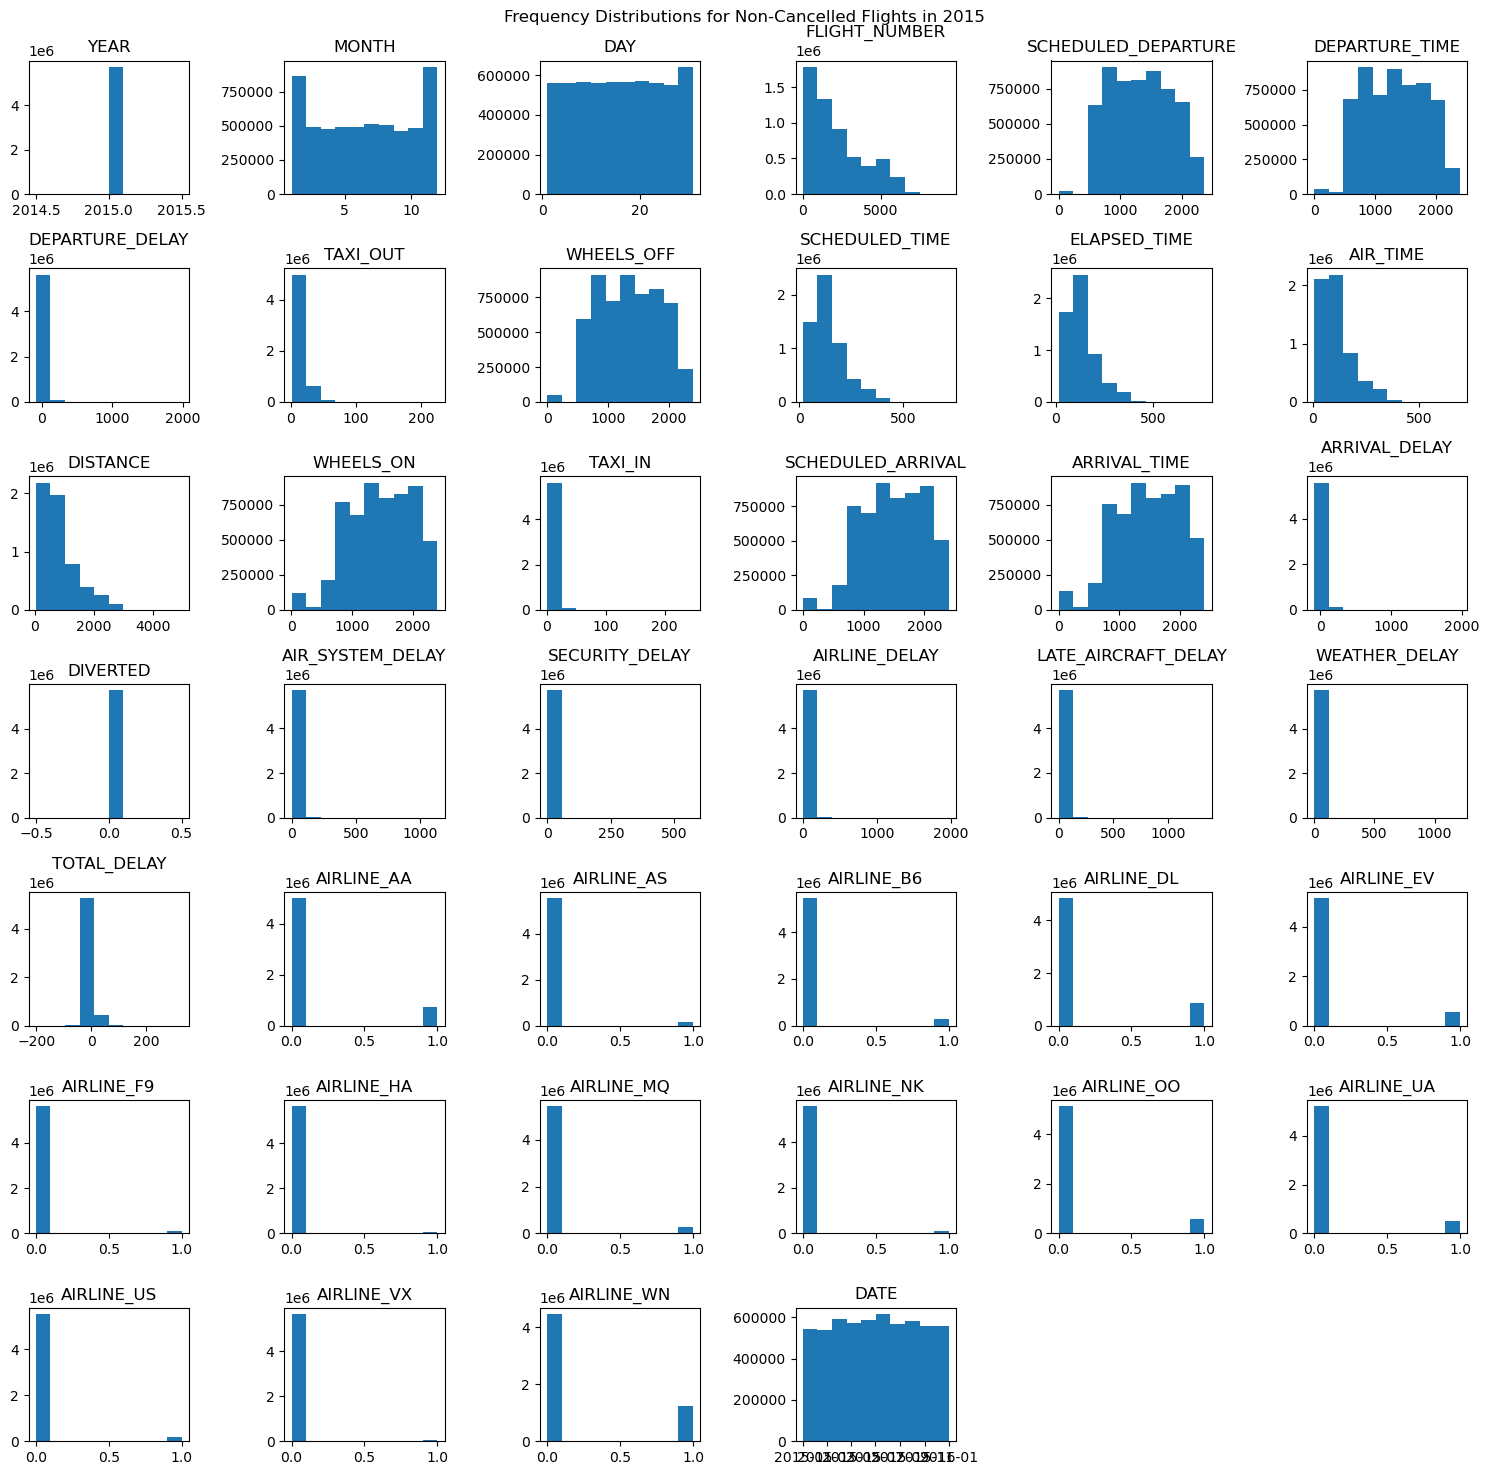

In [74]:
all15_nc.hist(figsize=(15, 15), grid = False)
plt.suptitle('Frequency Distributions for Non-Cancelled Flights in 2015')
plt.tight_layout();

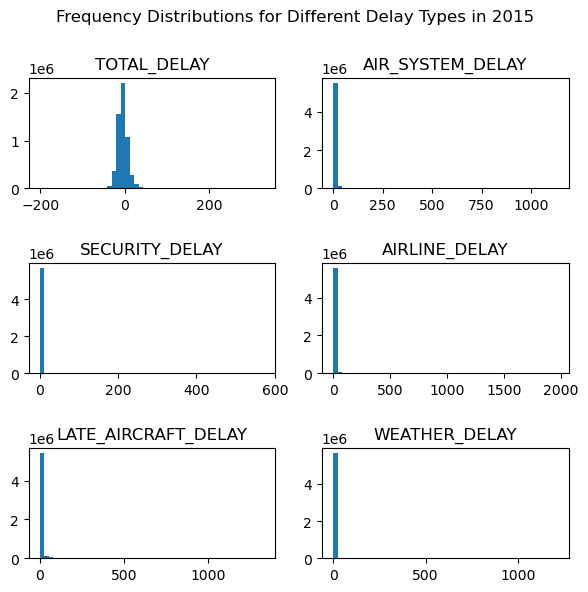

In [75]:
all15_nc[['TOTAL_DELAY', 'AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 
               'WEATHER_DELAY']].hist(figsize=(6, 6), bins = 50, grid = False)
plt.suptitle('Frequency Distributions for Different Delay Types in 2015')
plt.tight_layout();

In [76]:
all15_nc.SECURITY_DELAY.value_counts(normalize = True)

SECURITY_DELAY
0.0      9.993903e-01
15.0     2.765134e-05
8.0      2.222608e-05
10.0     2.187606e-05
12.0     2.170105e-05
             ...     
149.0    1.750085e-07
87.0     1.750085e-07
364.0    1.750085e-07
144.0    1.750085e-07
105.0    1.750085e-07
Name: proportion, Length: 154, dtype: float64

Most of the variables are category adjacent or military-time vars, so we're focusing on the delay columns and flight distance for non-delayed flights, histograms/violin plots

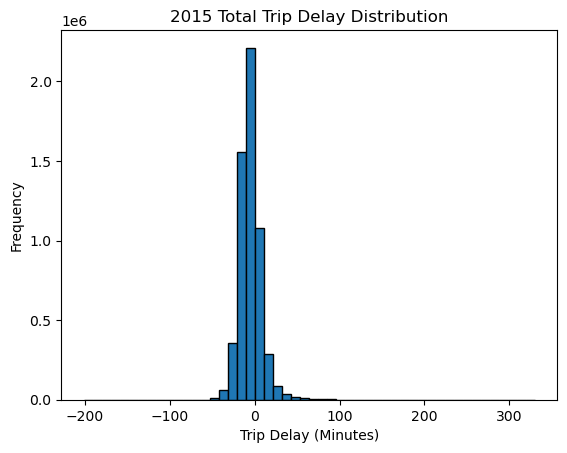

In [78]:
all15_nc.hist('TOTAL_DELAY', edgecolor = 'black', bins = 50, grid = False)
plt.xlabel('Trip Delay (Minutes)')
plt.ylabel('Frequency')
plt.title('2015 Total Trip Delay Distribution');

In [79]:
print('Max total delay:', max(all15_nc.TOTAL_DELAY), 'minutes')
print('Min total delay:', min(all15_nc.TOTAL_DELAY), 'minutes')

Max total delay: 330.0 minutes
Min total delay: -201.0 minutes


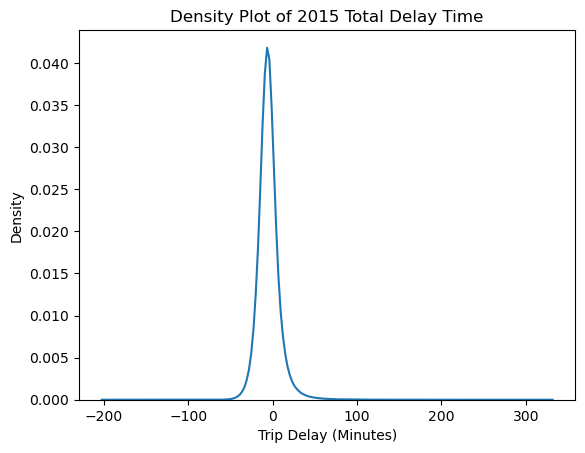

In [80]:
sns.kdeplot(all15_nc.TOTAL_DELAY)
plt.xlabel('Trip Delay (Minutes)')
plt.ylabel('Density')
plt.title('Density Plot of 2015 Total Delay Time');

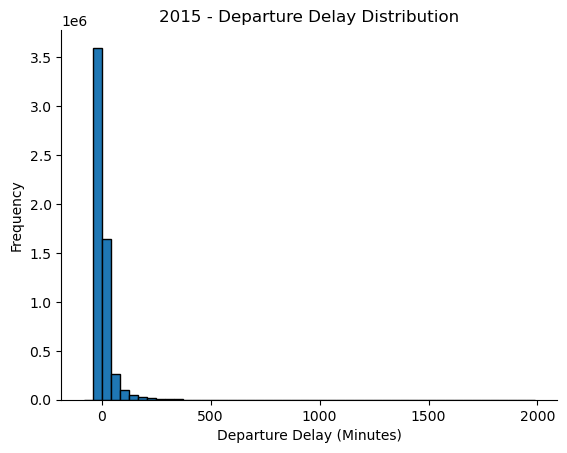

In [227]:
all15_nc.hist('DEPARTURE_DELAY', edgecolor = 'black', bins = 50, grid = False)
plt.xlabel('Departure Delay (Minutes)')
plt.ylabel('Frequency')
plt.title('2015 - Departure Delay Distribution');

In [82]:
print('Max departure delay:', max(all15_nc.DEPARTURE_DELAY), 'minutes')
print('Min departure delay:', min(all15_nc.DEPARTURE_DELAY), 'minutes')

Max departure delay: 1988.0 minutes
Min departure delay: -82.0 minutes


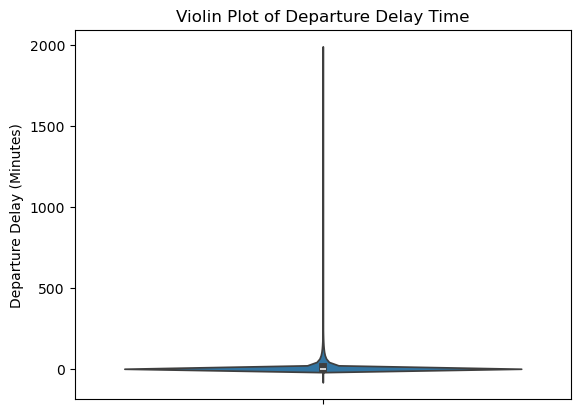

In [83]:
sns.violinplot(all15_nc.DEPARTURE_DELAY)
plt.ylabel('Departure Delay (Minutes)')
plt.title('Violin Plot of Departure Delay Time');

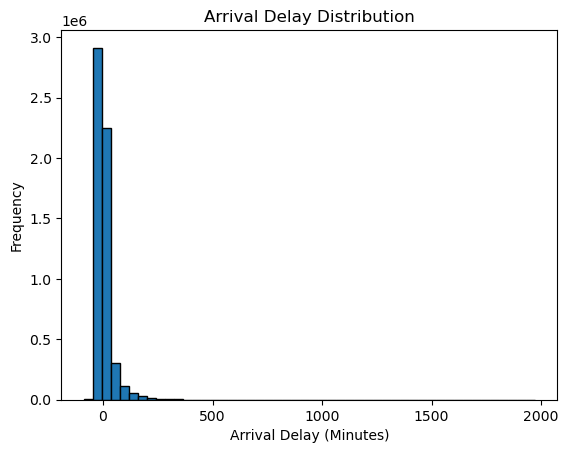

In [84]:
all15_nc.hist('ARRIVAL_DELAY', edgecolor = 'black', bins = 50, grid = False)
plt.xlabel('Arrival Delay (Minutes)')
plt.ylabel('Frequency')
plt.title('Arrival Delay Distribution');

In [85]:
print('Max arrival delay:', max(all15_nc.ARRIVAL_DELAY), 'minutes')
print('Min arrival delay:', min(all15_nc.ARRIVAL_DELAY), 'minutes')

Max arrival delay: 1971.0 minutes
Min arrival delay: -87.0 minutes


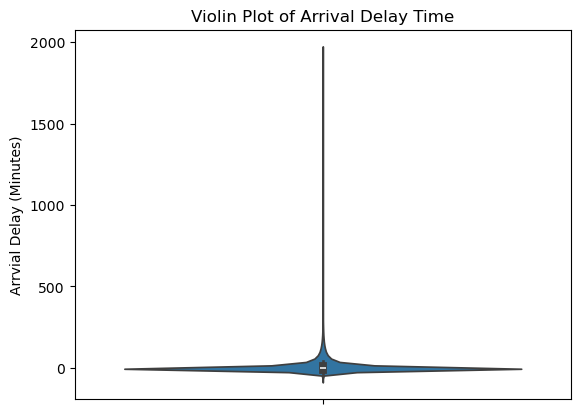

In [86]:
sns.violinplot(all15_nc.ARRIVAL_DELAY)
plt.ylabel('Arrvial Delay (Minutes)')
plt.title('Violin Plot of Arrival Delay Time');

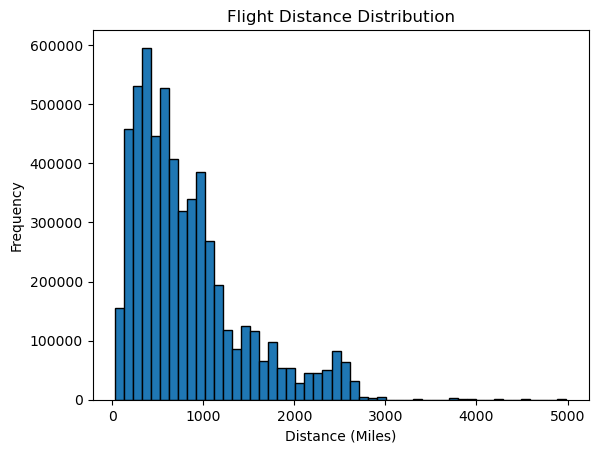

In [87]:
all15_nc.hist('DISTANCE', edgecolor = 'black', bins = 50, grid = False)
plt.xlabel('Distance (Miles)')
plt.ylabel('Frequency')
plt.title('Flight Distance Distribution');

In [88]:
print('Longest flight distance:', max(all15_nc.DISTANCE), 'miles')
print('Shortest flight distance:', min(all15_nc.DISTANCE), 'miles')

Longest flight distance: 4983 miles
Shortest flight distance: 31 miles


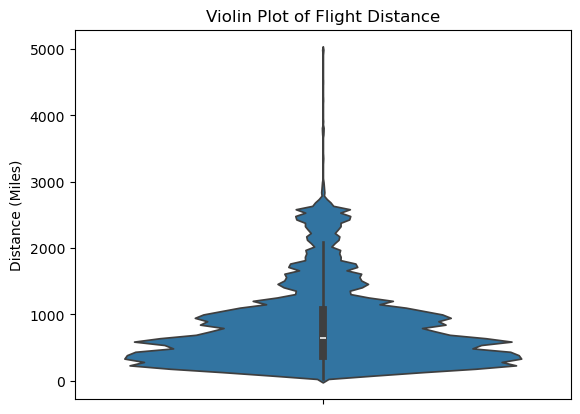

In [89]:
sns.violinplot(all15_nc.DISTANCE)
plt.ylabel('Distance (Miles)')
plt.title('Violin Plot of Flight Distance');

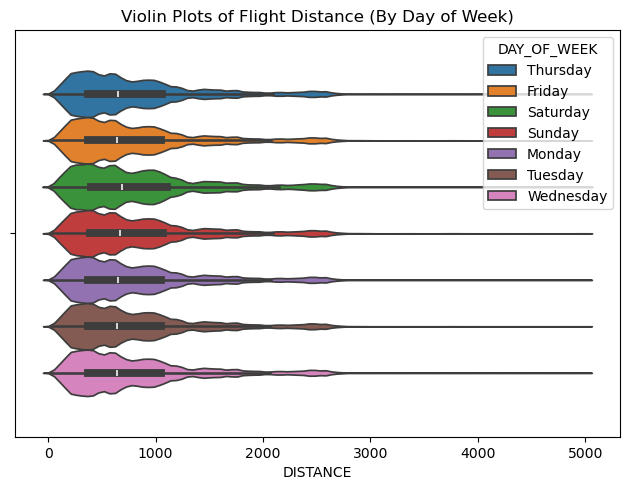

In [90]:
sns.violinplot(data=all15_nc, x="DISTANCE", hue="DAY_OF_WEEK")
plt.tight_layout()
plt.title('Violin Plots of Flight Distance (By Day of Week)');

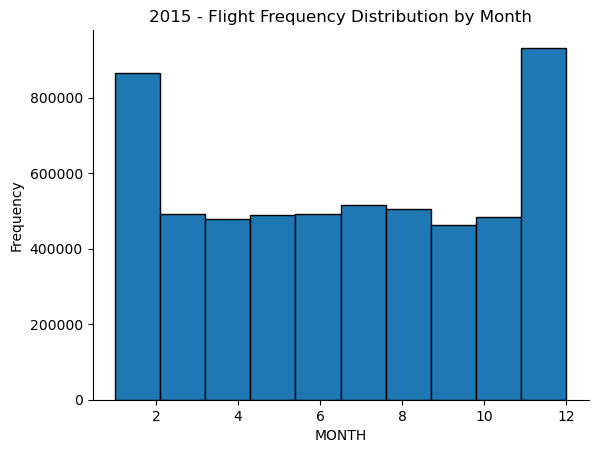

In [229]:
all15_nc.hist('MONTH', edgecolor = 'black', bins = 10, grid = False)
plt.xlabel('MONTH')
plt.ylabel('Frequency')
plt.title('2015 - Flight Frequency Distribution by Month');

What we're seeing from the histograms & density plots for the non-cancelled flights:

- TOTAL_DELAY variable that we created looks to be pretty normally distributed
- In general, the vast majority of flights were not delayed, (a little under 10% of flights experienced a non-zero delay of any kind)
- Histograms for DISTANCE, ARRIVAL_DELAY and DEPARTURE_DELAY show right-skew; we're not really focusing on those, but this implies serious outliers
- Density plots for arrival and departure delay show the vast majority of the values being closer to 0 with largest values getting closer to 2000 minutes
- Majority of flights are less than 3000 miles, small percentage get up to as many as 5000 miles (distributions don't change much when we split the data up by day of week either)
- The distribution of flights appears to be exactly the same regardless of day
- The distribution of flights by month is multimodal; January (Month 1) and December (Month 12) stick out with highest frequency of flights. Holiday szn!

<h3> Outlier Detection with Box Plots </h3>

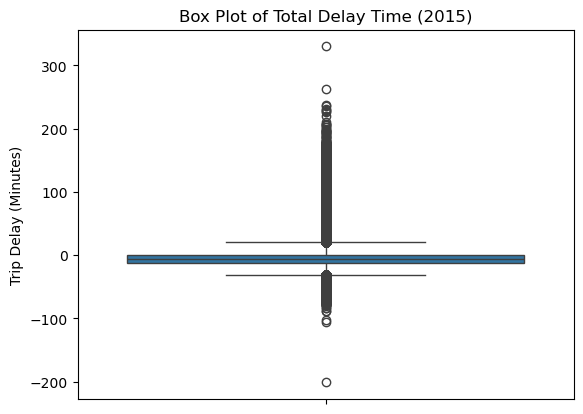

In [94]:
#Total Delay

sns.boxplot(all15_nc.TOTAL_DELAY)
plt.ylabel('Trip Delay (Minutes)')
plt.title('Box Plot of Total Delay Time (2015)');

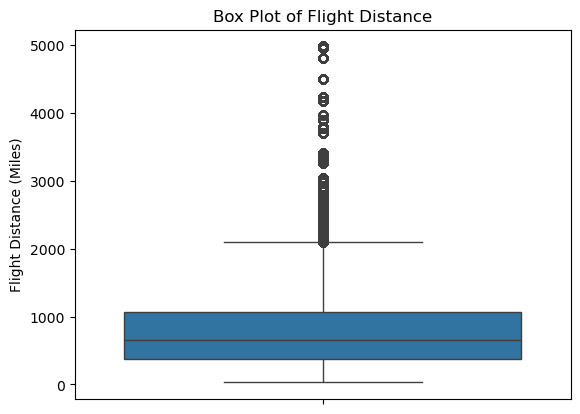

In [95]:
#DISTANCE

sns.boxplot(all15_nc.DISTANCE)
plt.ylabel('Flight Distance (Miles)')
plt.title('Box Plot of Flight Distance');

What we're seeing from outlier detection:

- TOTAL_DELAY and DISTANCE have a LOT of outliers. Standardization doesn't fix this
- Modeling Note: implementing a random forest algorithm (which is less sensitive to outliers) could work well with this dataset

In [97]:
mm = MinMaxScaler()

scaled = mm.fit_transform(all15_nc[['TOTAL_DELAY', 'DISTANCE']])

In [98]:
df_scaled = pd.DataFrame(scaled, columns=['TOTAL_DELAY', 'DISTANCE'])
df_scaled

,TOTAL_DELAY,DISTANCE
0,0.357815,0.286147
1,0.376648,0.464257
2,0.391714,0.457391
3,0.370998,0.466680
4,0.340866,0.286147
...,...,...
5714003,0.337100,0.521002
5714004,0.355932,0.320275
5714005,0.380414,0.316438
5714006,0.370998,0.233845


In [99]:
df_scaled.head()

,TOTAL_DELAY,DISTANCE
0,0.357815,0.286147
1,0.376648,0.464257
2,0.391714,0.457391
3,0.370998,0.466680
4,0.340866,0.286147


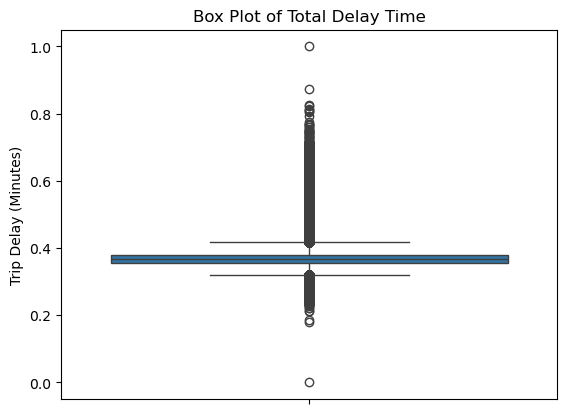

In [100]:
#Total Delay with scaled data

sns.boxplot(df_scaled.TOTAL_DELAY)
plt.ylabel('Trip Delay (Minutes)')
plt.title('Box Plot of Total Delay Time');

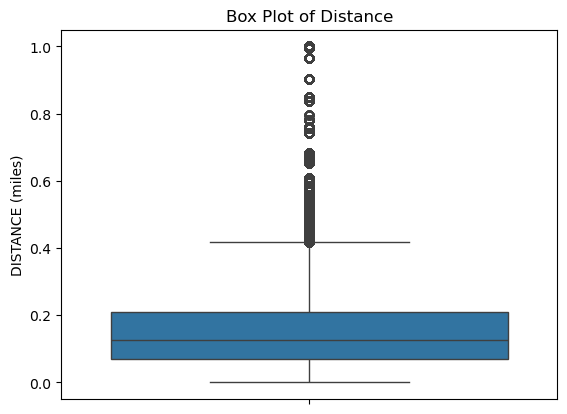

In [101]:
#Distance with scaled data

sns.boxplot(df_scaled.DISTANCE)
plt.ylabel('DISTANCE (miles)')
plt.title('Box Plot of Distance');

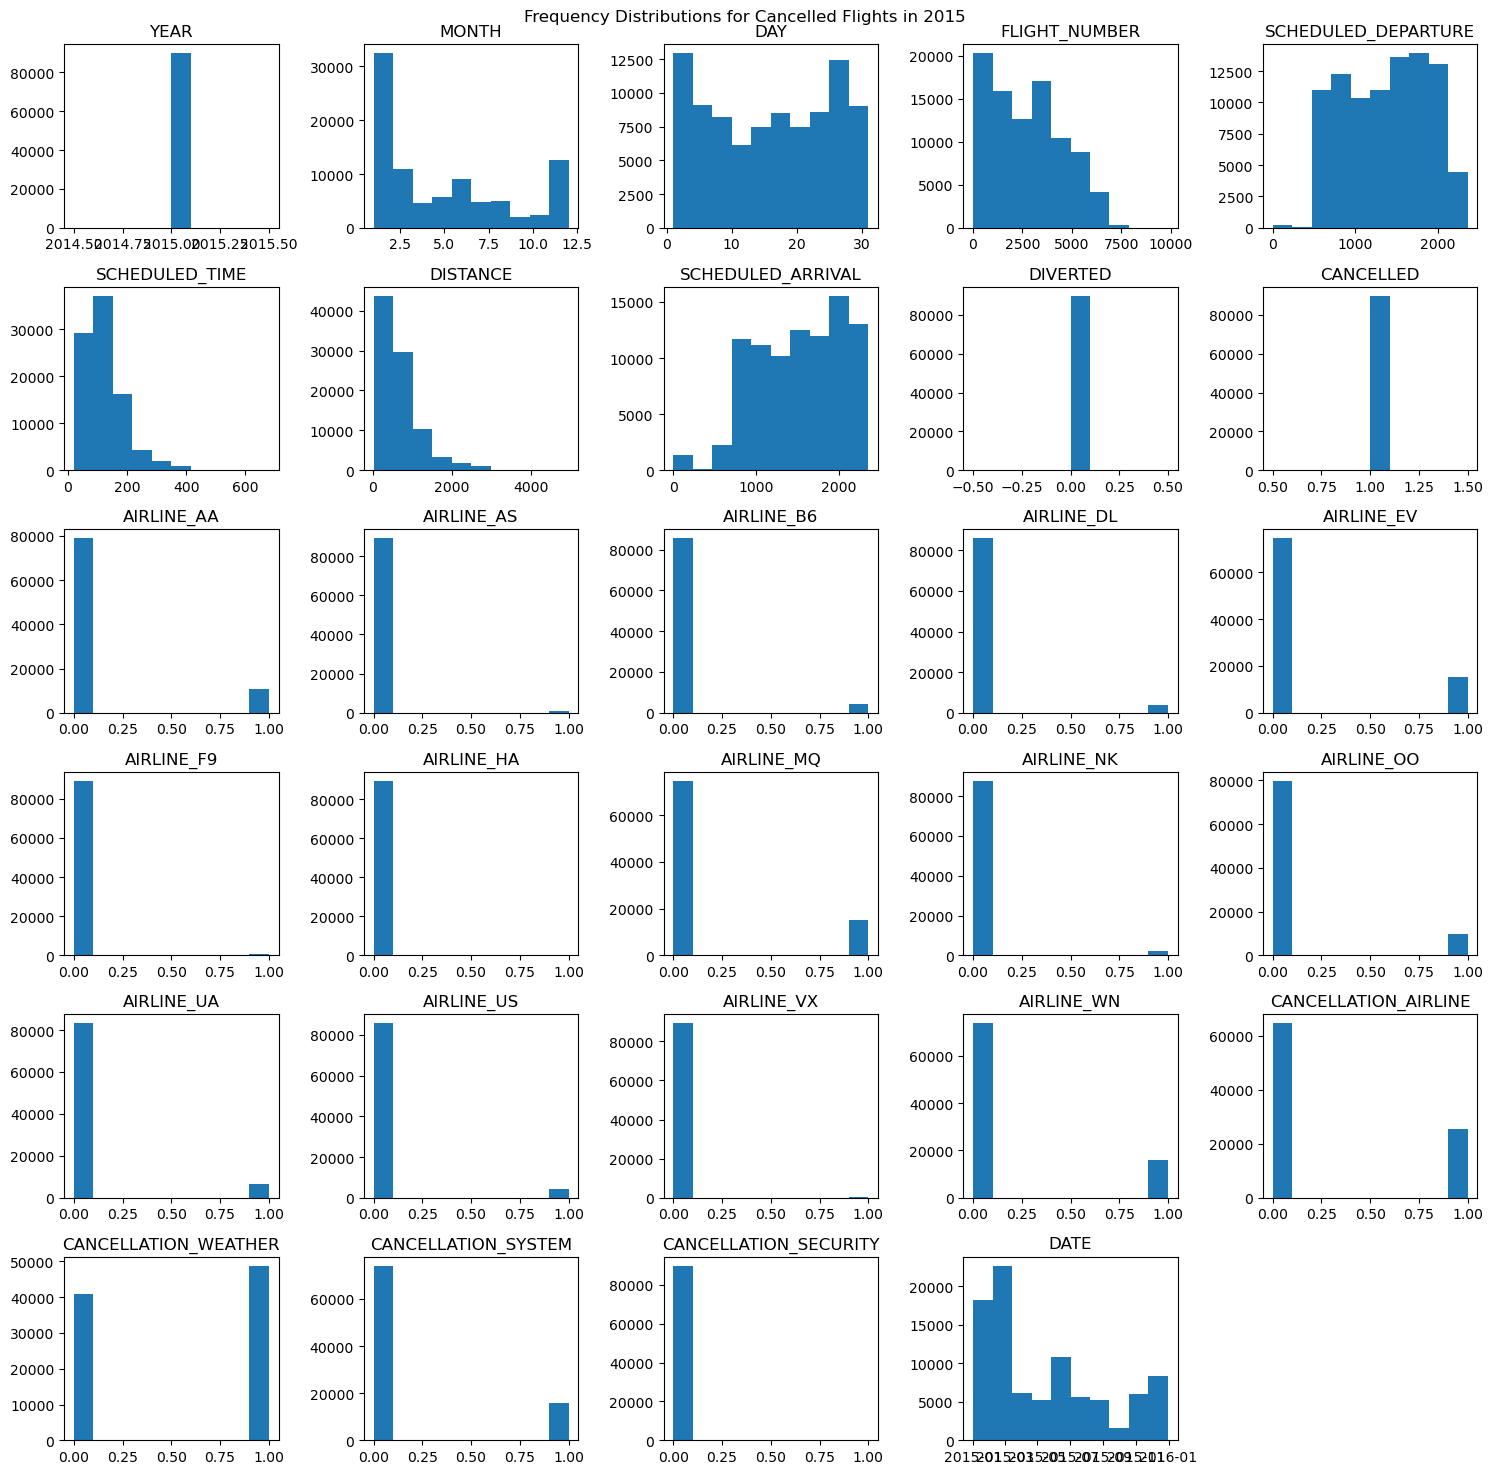

In [102]:
all15_c.hist(figsize=(15, 15), grid = False)
plt.suptitle('Frequency Distributions for Cancelled Flights in 2015')
plt.tight_layout();

<h3>Bar Plots</h3>

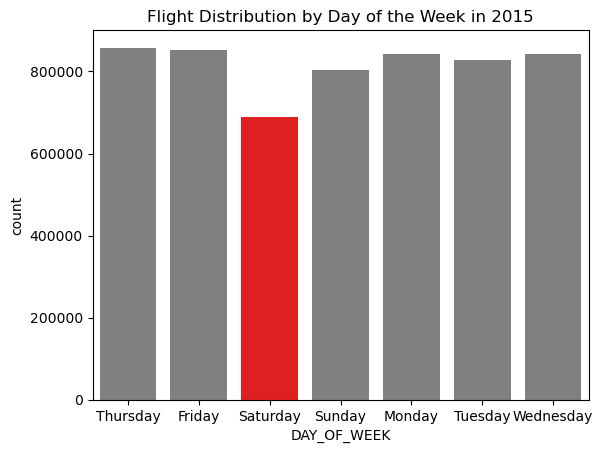

In [104]:
#day of week

#Bar Plot showing total counts of each day of week in the dataset

colors = ['red' if day == 'Saturday' else "grey" for day in all15_nc['DAY_OF_WEEK'].unique()]

sns.countplot(x= 'DAY_OF_WEEK', hue = 'DAY_OF_WEEK', data = all15_nc, legend = False, palette = colors)
plt.title('Flight Distribution by Day of the Week in 2015')

#Removing Frame
plt.rcParams['axes.spines.left'] = True
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.bottom'] = True
plt.show();

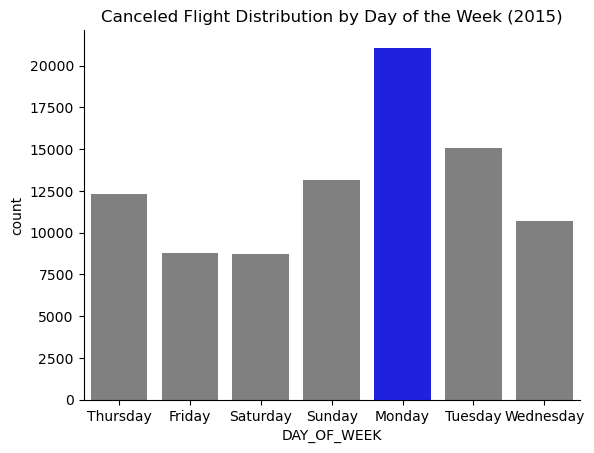

In [105]:
#Bar Plot showing total counts of each day of week in the dataset

colors = ['blue' if day == 'Monday' else "grey" for day in all15_c['DAY_OF_WEEK'].unique()]

sns.countplot(x= 'DAY_OF_WEEK', hue = 'DAY_OF_WEEK', data = all15_c, legend = False, palette = colors)
    
plt.title('Canceled Flight Distribution by Day of the Week (2015)')

#Removing Frame
plt.rcParams['axes.spines.left'] = True
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.bottom'] = True
plt.show();

In [106]:
# day of week goes from 1 to 7, 1 being monday

# Define the mapping
reason_mapping = {
    'A': 'Airline/Carrier',
    'B': 'Weather',
    'C': 'National Air System',
    'D': 'Security'
}

# Use the .replace() method to map the numbers to text
all15_c['CANCELLATION_REASON'] = all15_c['CANCELLATION_REASON'].replace(reason_mapping)

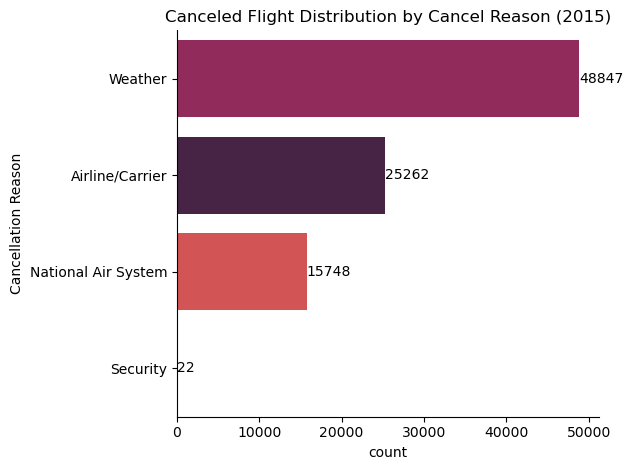

In [107]:
#Bar Plot showing total counts of cancellation reasons

ax = sns.countplot(y= 'CANCELLATION_REASON', hue = 'CANCELLATION_REASON', order=all15_c.CANCELLATION_REASON.value_counts().index,
              palette = 'rocket', data = all15_c)

for container in ax.containers: #for labeling bars
    ax.bar_label(container)

plt.ylabel('Cancellation Reason')
plt.title('Canceled Flight Distribution by Cancel Reason (2015)')

#Removing Frame
plt.rcParams['axes.spines.left'] = True
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.bottom'] = True
plt.tight_layout()
plt.show();

In [108]:
all15_c.CANCELLATION_REASON.value_counts(normalize = True)

CANCELLATION_REASON
Weather                0.543475
Airline/Carrier        0.281067
National Air System    0.175213
Security               0.000245
Name: proportion, dtype: float64

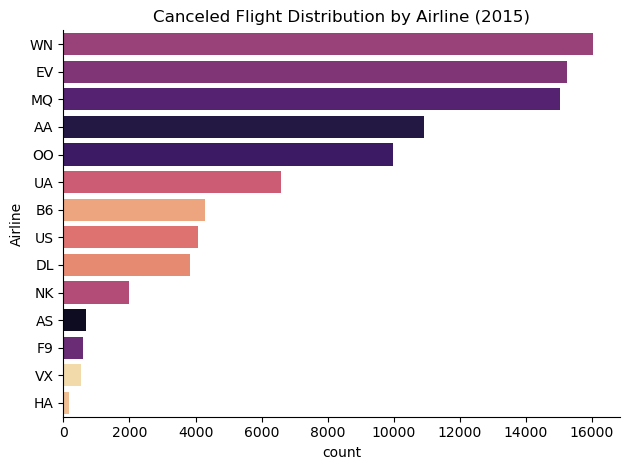

In [109]:
#Bar Plot showing total counts of airlines


ax = sns.countplot(y= 'AIRLINE', hue = 'AIRLINE', order=all15_c.AIRLINE.value_counts().index,
              palette = 'magma', data = all15_c)


plt.ylabel('Airline')
plt.title('Canceled Flight Distribution by Airline (2015)')

#Removing Frame
plt.rcParams['axes.spines.left'] = True
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.bottom'] = True
plt.tight_layout()
plt.show();

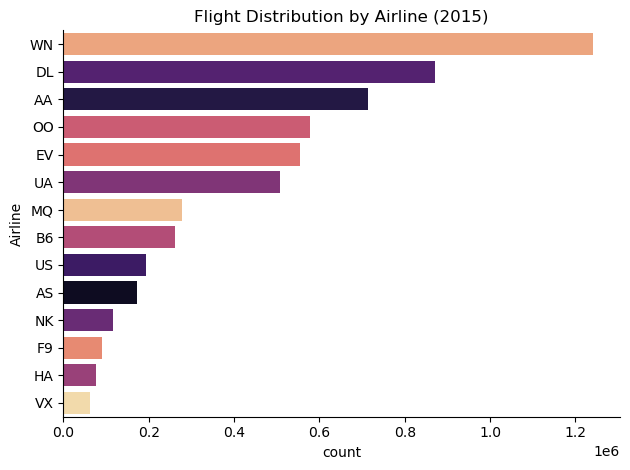

In [110]:
#Bar Plot showing total counts of airlines


ax = sns.countplot(y= 'AIRLINE', hue = 'AIRLINE', order=all15_nc.AIRLINE.value_counts().index,
              palette = 'magma', data = all15_nc)


plt.ylabel('Airline')
plt.title('Flight Distribution by Airline (2015)')

plt.tight_layout()
plt.show();

What we found from bar charts:

- For non-cancelled flights, pretty even distribution of flights by day. The least flights in 2015 occur on Saturday, but not by a super significant amount
- Conversely, the most common day for canceled flights in 2015 occur on Mondays with over 20000 flights
- The clear most common reason for a flight to be canceled in 2015 is weather, with 54.3% of the almost 90,000 cancelled flights being cancelled for this reason
- 22 flights were cancelled for security reasons. While ideally this number would be 0, figure tells us that security is not a main driver at all and that flights are almost guaranteed to be safe
- Airlines with the top 5 most cancelled flights: WN (Southwest Airlines), DL (Delta), AA (American Airlines), OO (Skywest Airlines), EV (Atlantic Southeast Airlines)
- Airlines with the top 5 most cancelled flights: WN (Southwest Airlines), EV (Atlantic Southeast), MQ (American Eagle Airlines), AA (American Airlines), OO (Skywest Airlines)

<h3> Means, Medians, Modes </h3>

In [113]:
#for non-cancelled flights
means_nc = all15_nc[['TOTAL_DELAY', 'DEPARTURE_DELAY', 'ARRIVAL_DELAY', 'AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 
               'WEATHER_DELAY']].mean()
means_nc

TOTAL_DELAY           -4.887785
DEPARTURE_DELAY        9.294842
ARRIVAL_DELAY          4.407057
AIR_SYSTEM_DELAY       2.508880
SECURITY_DELAY         0.014173
AIRLINE_DELAY          3.530439
LATE_AIRCRAFT_DELAY    4.368550
WEATHER_DELAY          0.542567
dtype: float64

In [114]:
medians_nc = all15_nc[['TOTAL_DELAY', 'DEPARTURE_DELAY', 'ARRIVAL_DELAY', 'AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 
               'WEATHER_DELAY']].median()
medians_nc

TOTAL_DELAY           -6.0
DEPARTURE_DELAY       -2.0
ARRIVAL_DELAY         -5.0
AIR_SYSTEM_DELAY       0.0
SECURITY_DELAY         0.0
AIRLINE_DELAY          0.0
LATE_AIRCRAFT_DELAY    0.0
WEATHER_DELAY          0.0
dtype: float64

What we found from means and medians report:

- The average total trip delay is actually slightly negative (about 5 minutes early on average), but the averages of every other delay are all positive (indicating lateness)
- The median values for each specific type of delay are all 0, but the medians for total trip delay, arrival and departure delay are all negative (indicating a flight being early)

<h3> Bivariate Analysis (mainly for delayed flights)</h3>

<h3> Correlation Analysis</h3>

In [118]:
number15= all15_nc.drop(['YEAR', 'MONTH', 'DAY', 'DAY_OF_WEEK', 'FLIGHT_NUMBER', 'AIRLINE',
                         'TAIL_NUMBER', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'SCHEDULED_DEPARTURE',
                        'DEPARTURE_TIME', 'WHEELS_OFF', 'WHEELS_ON', 'SCHEDULED_ARRIVAL',
                        'ARRIVAL_TIME', 'DATE', 'DIVERTED'], axis =1) #creating df of numeric columns only to run correlation matrix

corrs = number15.corr()

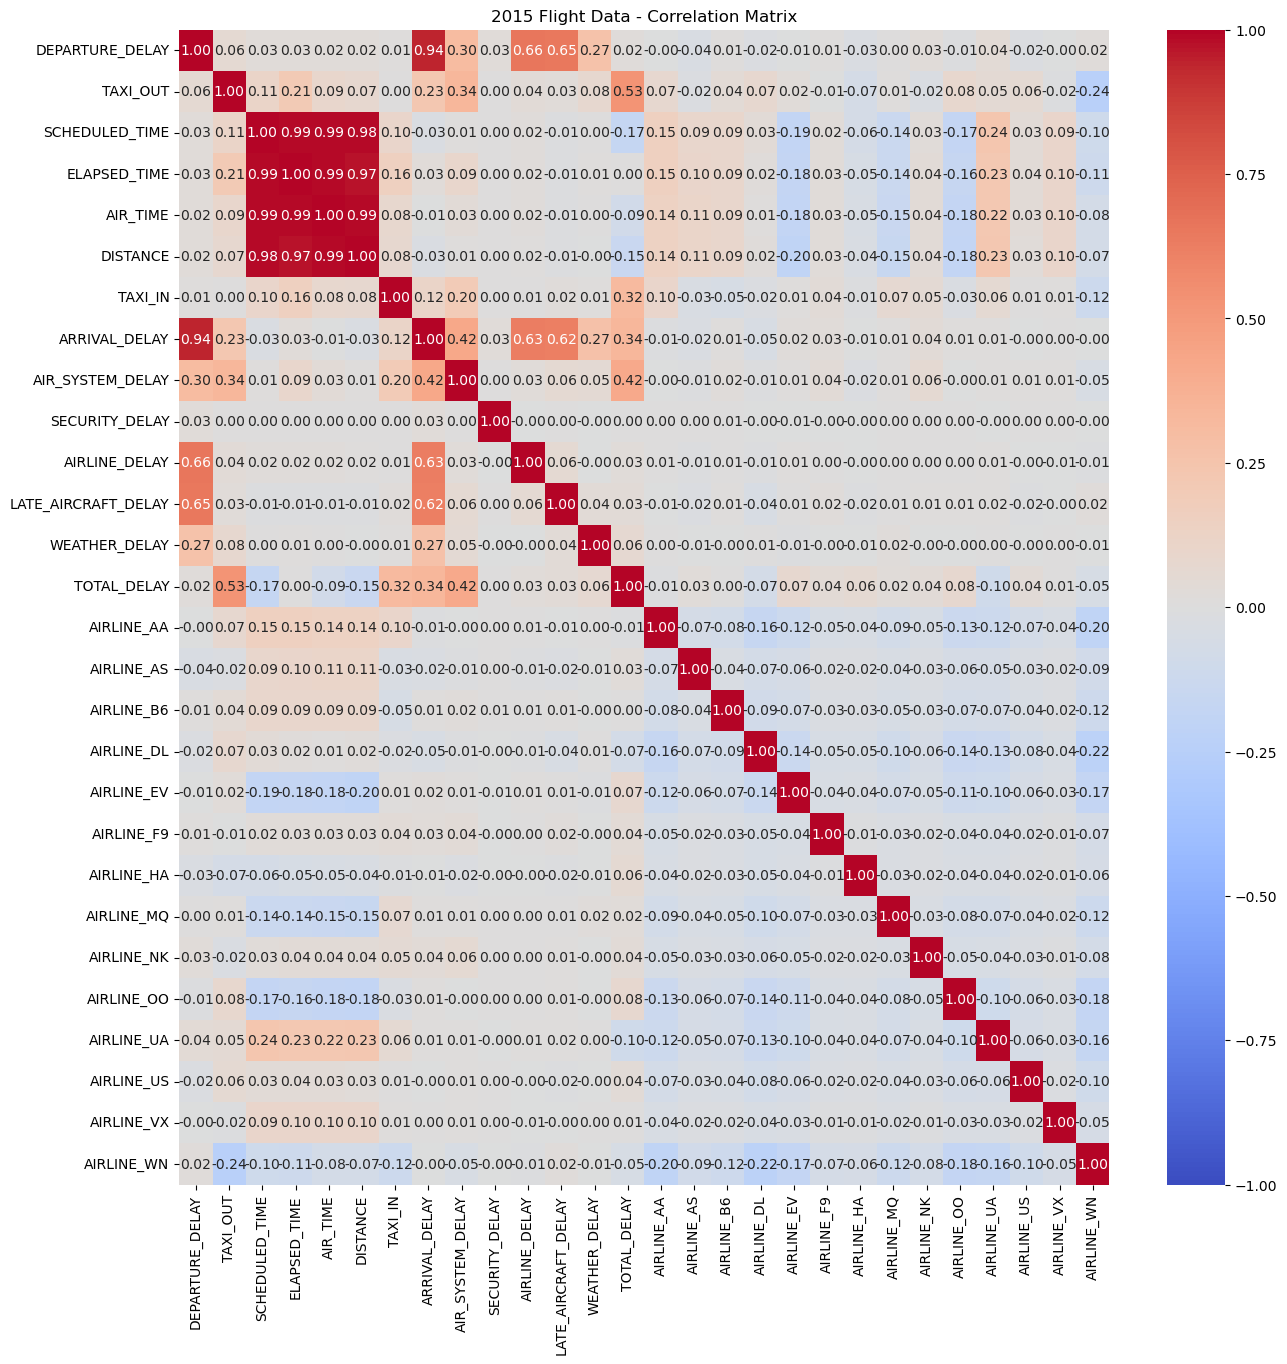

In [119]:
plt.figure(figsize=(15, 15))

# Making a heatmap
sns.heatmap(corrs,
            annot=True,     # Annotate each cell with the correlation value
            fmt=".2f",      # Set the annotation format to two decimal places
            cmap='coolwarm',# Choose a divergent color map
            vmin=-1, vmax=1,# Ensure the color scale ranges from -1 to 1
            center=0        # Center the color map at 0
           )

# Display the plot
plt.title('2015 Flight Data - Correlation Matrix')
plt.show()

What we see:

- Arrival and Departure delay seem to be almost perfectly correlated (makes sense)
- Our created target variable TOTAL_DELAY: 2 highest positive correlations are with TAXI_OUT (0.53) and AIR_SYSTEM_DELAY (0.42)
- The original target variables: ARRIVAL_DELAY highly correlated with AIRLINE_DELAY (0.63) and LATE_AIRCRAFT_DELAY (0.62), DEPARTURE_DELAY highly correlated with AIRLINE_DELAY (0.66) and LATE_AIRCRAFT_DELAY (0.65)
- Distance not highly correlated with anything
- None of the encoded airline variables are super strongly correlated with our targets

<h3> Scatterplots on Notable Correlations </h3>

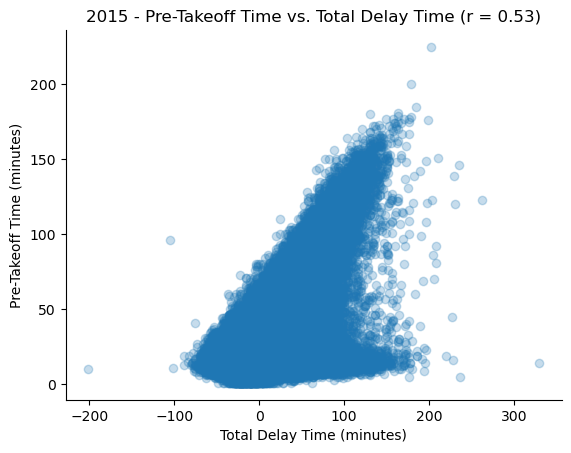

In [122]:
# TOTAL_DELAY, TAXI_OUT - r = 0.53

plt.scatter(all15_nc.TOTAL_DELAY, all15_nc.TAXI_OUT, alpha = 0.25)
plt.xlabel('Total Delay Time (minutes)')
plt.ylabel('Pre-Takeoff Time (minutes)')
plt.title('2015 - Pre-Takeoff Time vs. Total Delay Time (r = 0.53)')
plt.show()

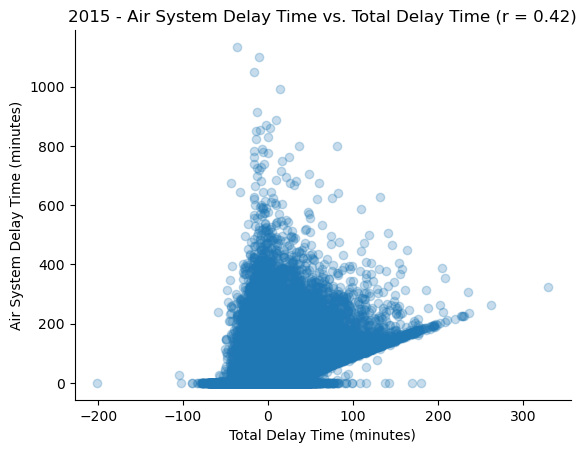

In [123]:
# TOTAL_DELAY, AIR_SYSTEM_DELAY - r = 0.42

plt.scatter(all15_nc.TOTAL_DELAY, all15_nc.AIR_SYSTEM_DELAY, alpha = 0.25)
plt.xlabel('Total Delay Time (minutes)')
plt.ylabel('Air System Delay Time (minutes)')
plt.title('2015 - Air System Delay Time vs. Total Delay Time (r = 0.42)')
plt.show()

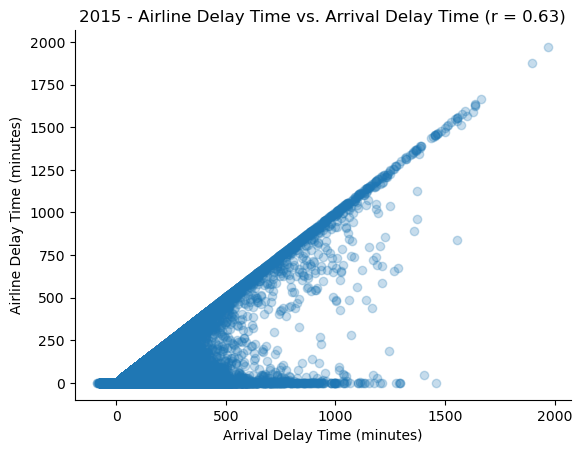

In [124]:
# ARRIVAL_DELAY, AIRLINE_DELAY - r = 0.63

plt.scatter(all15_nc.ARRIVAL_DELAY, all15_nc.AIRLINE_DELAY, alpha = 0.25)
plt.xlabel('Arrival Delay Time (minutes)')
plt.ylabel('Airline Delay Time (minutes)')
plt.title('2015 - Airline Delay Time vs. Arrival Delay Time (r = 0.63)')
plt.show()

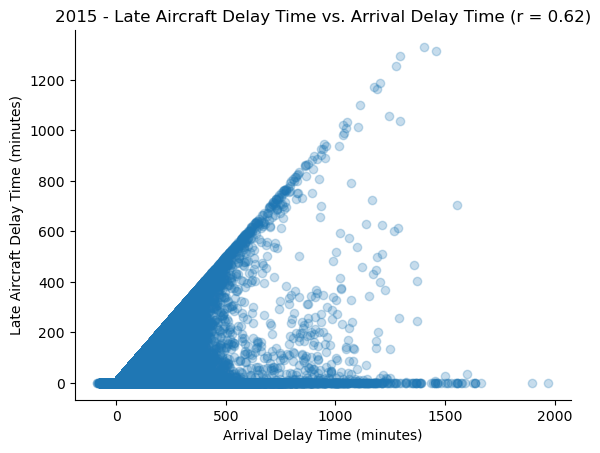

In [125]:
plt.scatter(all15_nc.ARRIVAL_DELAY, all15_nc.LATE_AIRCRAFT_DELAY, alpha = 0.25)
plt.xlabel('Arrival Delay Time (minutes)')
plt.ylabel('Late Aircraft Delay Time (minutes)')
plt.title('2015 - Late Aircraft Delay Time vs. Arrival Delay Time (r = 0.62)')
plt.show()

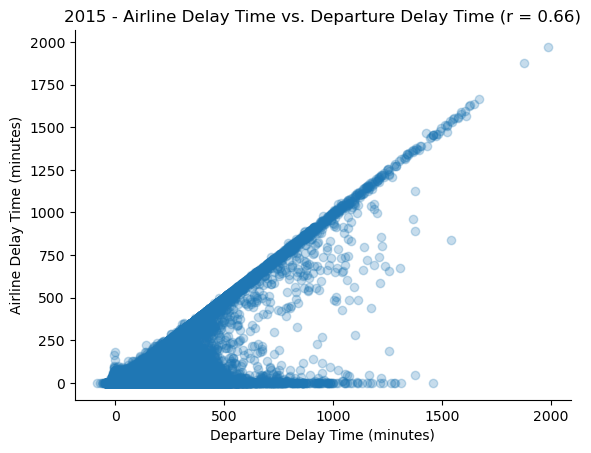

In [126]:
# DEPARTURE_DELAY, AIRLINE_DELAY - r = 0.66

plt.scatter(all15_nc.DEPARTURE_DELAY, all15_nc.AIRLINE_DELAY, alpha = 0.25)
plt.xlabel('Departure Delay Time (minutes)')
plt.ylabel('Airline Delay Time (minutes)')
plt.title('2015 - Airline Delay Time vs. Departure Delay Time (r = 0.66)')
plt.show()

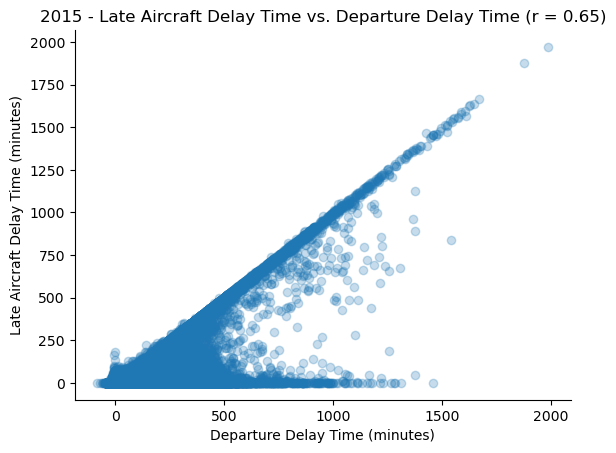

In [127]:
# DEPARTURE_DELAY, AIRLINE_DELAY - r = 0.65

plt.scatter(all15_nc.DEPARTURE_DELAY, all15_nc.AIRLINE_DELAY, alpha = 0.25)
plt.xlabel('Departure Delay Time (minutes)')
plt.ylabel('Late Aircraft Delay Time (minutes)')
plt.title('2015 - Late Aircraft Delay Time vs. Departure Delay Time (r = 0.65)')
plt.show()

cool shapes on these!

<h3> Pairplots </h3>

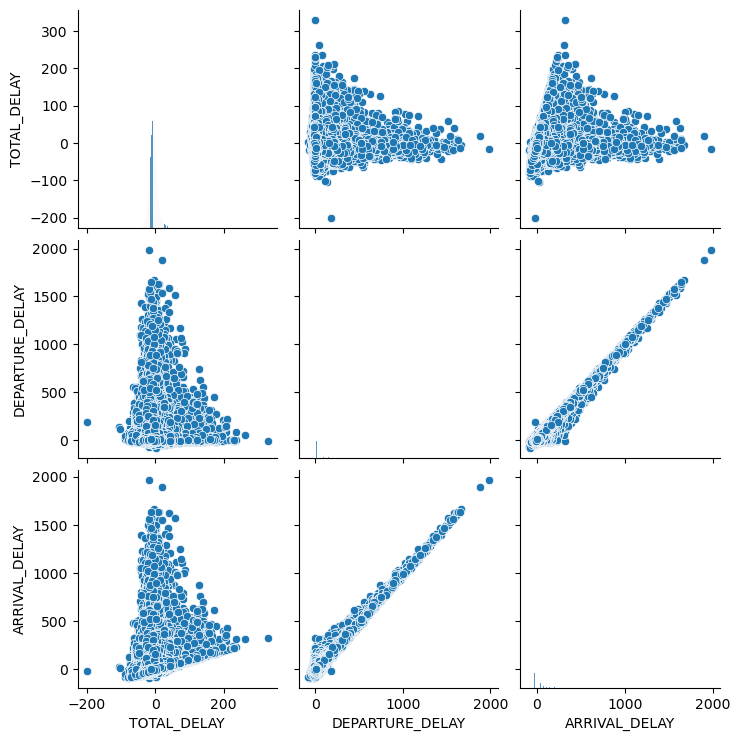

In [130]:
delays = all15_nc[['TOTAL_DELAY', 'DEPARTURE_DELAY', 'ARRIVAL_DELAY']] #delay
sns.pairplot(delays)
plt.show()

not much with the pairplots...

<h3>Line Plots/Time Series</h3>

shoot for monthly average delay times

In [134]:
months = all15_nc.groupby(['MONTH'])[['TOTAL_DELAY', 'ARRIVAL_DELAY', 'DEPARTURE_DELAY', 'AIRLINE_DELAY',
                                     'AIR_SYSTEM_DELAY', 'WEATHER_DELAY', 'SECURITY_DELAY', 
                                      'LATE_AIRCRAFT_DELAY']].mean().reset_index()
months

,MONTH,TOTAL_DELAY,ARRIVAL_DELAY,DEPARTURE_DELAY,AIRLINE_DELAY,AIR_SYSTEM_DELAY,WEATHER_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY
0,1,-3.876128,5.813583,9.689711,3.737651,2.796540,0.575666,0.014660,4.778562
1,2,-3.455207,8.320500,11.775707,4.201166,3.309530,1.008836,0.011235,5.293387
2,3,-4.656704,4.920673,9.577377,3.695468,2.497050,0.464628,0.013382,4.381068
3,4,-4.466505,3.163190,7.629695,3.110257,2.332863,0.462367,0.007637,3.725474
4,5,-4.878580,4.485019,9.363599,3.406414,2.562392,0.687351,0.011664,4.436967
5,6,-4.272237,9.601590,13.873827,4.659322,3.309076,0.772449,0.014374,6.200375
6,7,-4.915514,6.431775,11.347285,3.929708,2.611774,0.451935,0.013261,5.409152
7,8,-5.264372,4.607372,9.871745,3.610629,2.529195,0.527411,0.023798,4.453732
8,9,-5.569298,-0.772571,4.796727,2.546323,1.702079,0.296532,0.012913,2.564441
9,10,-5.724187,-0.780390,4.943797,2.497548,1.662318,0.226196,0.006296,2.473206


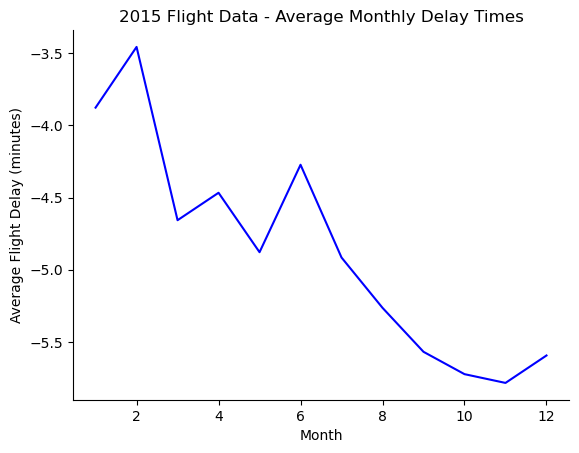

In [135]:
plt.plot(months.MONTH, months.TOTAL_DELAY, color = 'blue')
plt.xlabel('Month')
plt.ylabel('Average Flight Delay (minutes)')
plt.title('2015 Flight Data - Average Monthly Delay Times')
plt.show()

What we found:

- Overall, average delay time of flights steadily decreases past June of 2015
- All the monthly averages of this variable are slightly negative (arrival and departure delay averages are still positive)

OVERALL Figures to use:

- 2015 Trip Distribution
- 2015 Canceled Flights by Reason
- 2015 Monthly Average Delay Times